In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
data = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(data)

In [5]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [14]:
df.columns


Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [15]:
target="converted"
categorical = ["employment_status", "lead_source",'industry','location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']

In [25]:
df[categorical] = df[categorical].fillna("NA")

In [28]:
df[numerical] = df [numerical].fillna(0)

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [34]:
df[target]

0       1
1       1
2       1
3       0
4       1
       ..
4995    1
4996    0
4997    1
4998    1
4999    1
Name: converted, Length: 5000, dtype: int64

In [45]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

In [46]:
for feature in numerical:

    res = roc_auc_score(df_train[target], df_train[feature])
    print(f'{feature}: {res}')
    

annual_income: 0.6081977776250831
number_of_courses_viewed: 0.7229894623989618
interaction_count: 0.7649203047563227
lead_score: 0.7882254810906102


In [53]:
dv = DictVectorizer(sparse=False)
dicts = df_train[numerical+categorical].to_dict(orient='records')
X_train = dv.fit_transform(dicts)
Y_train = df_train[target]
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, Y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [58]:
X_val_dict = df_val[numerical+categorical].to_dict(orient='records')
X_val = dv.fit_transform(X_val_dict)
Y_val = df_val[target]
y_pred = model.predict_proba(X_val)[:, 1]

In [62]:
round(roc_auc_score(Y_val, y_pred),3)

0.732

In [65]:
tresholds = np.arange(0, 1., 0.01)
print(y_pred)

[0.54472295 0.79005207 0.50977909 0.52913949 0.82072027 0.54246
 0.50178717 0.54698398 0.82553299 0.40583754 0.91301567 0.33581825
 0.30789883 0.42704803 0.6219229  0.53665458 0.41931937 0.84087345
 0.79969125 0.61790114 0.61625181 0.68059931 0.85605897 0.8078487
 0.62046017 0.45970722 0.54556724 0.41221393 0.72714023 0.46812079
 0.77222191 0.79043883 0.61433884 0.78549759 0.49753426 0.66077291
 0.69804763 0.76896543 0.65657501 0.64127911 0.66509115 0.57942826
 0.67830946 0.61186114 0.86890227 0.4146967  0.84130129 0.74229365
 0.68028539 0.7189143  0.86417929 0.64043375 0.5424699  0.70225152
 0.27894903 0.70826494 0.62310718 0.47781771 0.37914032 0.69936035
 0.52032869 0.69977698 0.75148939 0.58087503 0.47001802 0.56863492
 0.91297185 0.79972028 0.82206546 0.36140197 0.66132404 0.52330065
 0.79295471 0.72068083 0.71234212 0.64595334 0.92090363 0.82174666
 0.72939868 0.68060557 0.4556843  0.76041067 0.59946674 0.82279814
 0.59782308 0.62356812 0.34591823 0.77925346 0.84520512 0.59397898

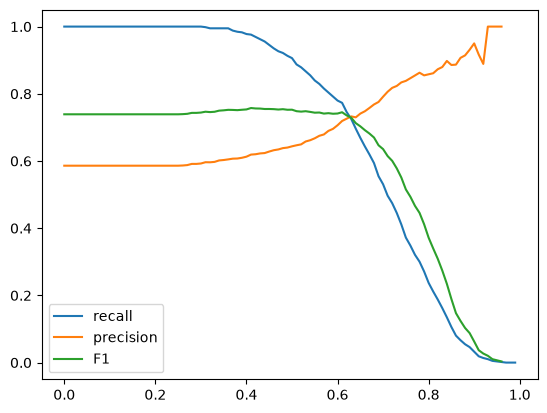

In [73]:
precision_list = []
recall_list= []
F1_list = []
for tr in tresholds:
    y_pred_binary = (y_pred>=tr)
    tp = (y_pred_binary & (Y_val==1)).sum()
    precision = (tp/y_pred_binary.sum()) if y_pred_binary.sum()>0 else np.nan
    recall = tp/(Y_val==1).sum() if (Y_val==1).sum()>0 else np.nan
    precision_list.append(precision)
    recall_list.append(recall)
    F1 = (2*precision*recall)/(precision+recall)
    F1_list.append(F1)
plt.plot(tresholds, recall_list, label="recall")
plt.plot(tresholds, precision_list, label="precision")
plt.plot(tresholds, F1_list, label="F1")
plt.legend()

In [75]:
from sklearn.model_selection import KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [79]:
auc_list = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]
    
    dv = DictVectorizer(sparse=False)
    dicts = df_train[numerical+categorical].to_dict(orient='records')
    X_train = dv.fit_transform(dicts)
    Y_train = df_train[target]
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, Y_train)

    X_val_dict = df_val[numerical+categorical].to_dict(orient='records')
    X_val = dv.transform(X_val_dict)
    Y_val = df_val[target]
    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(Y_val, y_pred)
    auc_list.append(auc)
auc_list

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [83]:
std = np.std(auc_list)
round(std,3)

np.float64(0.007)

In [87]:
C = [0.000001, 0.001, 1]
mean_list = []
std_list = []
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
for val in C:
    auc_list = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        
        dv = DictVectorizer(sparse=False)
        dicts = df_train[numerical+categorical].to_dict(orient='records')
        X_train = dv.fit_transform(dicts)
        Y_train = df_train[target]
        model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
        model.fit(X_train, Y_train)
    
        X_val_dict = df_val[numerical+categorical].to_dict(orient='records')
        X_val = dv.transform(X_val_dict)
        Y_val = df_val[target]
        y_pred = model.predict_proba(X_val)[:, 1]
    
        auc = roc_auc_score(Y_val, y_pred)
        auc_list.append(auc)
    mean_list.append(round(np.mean(auc_list),3))
    std_
mean_list

[np.float64(0.732), np.float64(0.732), np.float64(0.732)]